In [1]:
import os
import sys

from getpass import getpass

token = getpass("GitHub PAT: ")
os.environ["GITHUB_TOKEN"] = token

!git clone https://$GITHUB_TOKEN@github.com/Hanh3103/BA_USDependency.git

%cd /content/BA_USDependency

!git checkout Tool

current_dir = os.getcwd()
repo_root = current_dir
while not os.path.exists(os.path.join(repo_root, "app")):
    parent = os.path.dirname(repo_root)
    if parent == repo_root:  # Reached system root without finding it
        repo_root = os.path.abspath(os.path.join(current_dir, "..", "..", ".."))
        break
    repo_root = parent

app_path = os.path.abspath("app")
if app_path not in sys.path:
    sys.path.insert(0, app_path)

GitHub PAT: ··········
Cloning into 'BA_USDependency'...
remote: Enumerating objects: 1155, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 1155 (delta 6), reused 16 (delta 4), pack-reused 1133 (from 1)
Receiving objects: 100% (1155/1155), 2.28 MiB | 1.94 MiB/s, done.
Resolving deltas: 100% (586/586), done.
/content/BA_USDependency
Branch 'Tool' set up to track remote branch 'Tool' from 'origin'.
Switched to a new branch 'Tool'


In [40]:
!git config --global user.email "thiminhhanhnguyen.95@gmail.com"
!git config --global user.name "Hanh3103"

In [14]:
!git pull

remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 432 bytes | 144.00 KiB/s, done.
From https://github.com/Hanh3103/BA_USDependency
   6db2f9f..c3c0f5e  Tool       -> origin/Tool
Updating 6db2f9f..c3c0f5e
Fast-forward
 app/stages/annotation.py | 1 +
 1 file changed, 1 insertion(+)


In [41]:
!git add .
!git commit -m "Add RQ2 eval results: llama3.1:8b + qwen3:8b, annotation"
!git push https://$GITHUB_TOKEN@github.com/Hanh3103/BA_USDependency.git Tool

[Tool 64ca7cf] Add RQ2 eval results: llama3.1:8b + qwen3:8b, annotation
 4 files changed, 2574 insertions(+)
 create mode 100644 eval_with_colab/annotation/prediction/llama_pred_ann.json
 create mode 100644 eval_with_colab/annotation/prediction/llama_pred_ann_meta.json
 create mode 100644 eval_with_colab/annotation/prediction/qwen_pred_ann.json
 create mode 100644 eval_with_colab/annotation/prediction/qwen_pred_ann_meta.json
Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (9/9), 5.71 KiB | 2.85 MiB/s, done.
Total 9 (delta 4), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (4/4), completed with 2 local objects.
To https://github.com/Hanh3103/BA_USDependency.git
   c3c0f5e..64ca7cf  Tool -> Tool


In [2]:
print("Repo Root:", repo_root)
print("App Path added to sys.path:", app_path)

Repo Root: /content/BA_USDependency
App Path added to sys.path: /content/BA_USDependency/app


In [3]:
# 1. Install dependencies
!pip install -r app/requirements.txt

# 2. Re-create the .env file with required settings
env_content = """OLLAMA_BASE_URL=http://localhost:11434
OLLAMA_API_KEY=ollama
OLLAMA_MODELS=qwen3:8b,llama3.1:8b
OLLAMA_TEMPERATURE=0.0
OLLAMA_TOP_P=0.1
OLLAMA_NUM_PREDICT=2048
OLLAMA_NUM_CTX=8192
OLLAMA_KEEP_ALIVE=20m
OLLAMA_THINK=false
OLLAMA_FORMAT=json
"""

env_target = os.path.join(app_path, ".env")
with open(env_target, "w") as f:
    f.write(env_content.strip())

print(f"Wrote .env to: {env_target}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.8/62.8 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.5/71.5 kB 7.2 MB/s eta 0:00:00
  Attempting uninstall: uvicorn
    Found existing installation: uvicorn 0.52.4
    Uninstalling uvicorn-0.52.4:
      Successfully uninstalled uvicorn-0.52.4
  Attempting uninstall: starlette
    Found existing installation: starlette 1.6.0
    Uninstalling starlette-1.6.0:
      Successfully uninstalled starlette-1.6.0
  Attempting uninstall: httpx
    Found existing installation: httpx 0.28.1
    Uninstalling httpx-0.28.1:
      Successfully uninstalled httpx-0.28.1
  Attempting uninstall: fastapi
    Found existing installation: fastapi 0.141.1
    Uninstalling fastapi-0.141.1:
      Successfully u

In [4]:
!apt-get update -qq
!apt-get install -y zstd

# 1. Install Ollama binary
!curl -fsSL https://ollama.com/install.sh | sh

# 2. Launch background service with GPU and parallel execution settings
import subprocess
import time

env = os.environ.copy()
env["CUDA_VISIBLE_DEVICES"] = "0"
env["OLLAMA_KEEP_ALIVE"] = "-1"      # Keep models pinned in VRAM
env["OLLAMA_NUM_PARALLEL"] = "4"     # Enable parallel pipeline processing

ollama_process = subprocess.Popen(["ollama", "serve"], env=env)
time.sleep(5)  # Wait for server startup

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  zstd
0 upgraded, 1 newly installed, 0 to remove and 77 not upgraded.
Need to get 603 kB of archives.
After this operation, 1,695 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/main amd64 zstd amd64 1.4.8+dfsg-3build1 [603 kB]
Fetched 603 kB in 2s (332 kB/s)
Selecting previously unselected package zstd.
(Reading database ... 122579 files and directories currently installed.)
Preparing to unpack .../zstd_1.4.8+dfsg-3build1_amd64.deb ...
Unpacking zstd (1.4.8+dfsg-3build1) ...
Setting up zstd (1.4.8+dfsg-3build1) ...
Processing triggers for man-db (2.10.2-1) ...
>>> Installing ollama to /usr/local
>>> Downloading ollama-l

In [5]:
from config import settings
import subprocess

for model in settings.models:
    model = model.strip()
    print(f"Pulling {model}...")
    result = subprocess.run(["ollama", "pull", model], capture_output=True, text=True)
    if result.returncode != 0:
        print(f"FAILED to pull {model}:\n{result.stderr}")
    else:
        print(f"OK: {model}")

ENV path: /content/BA_USDependency/app/.env
ENV exists: True
ENV values: OrderedDict({'OLLAMA_BASE_URL': 'http://localhost:11434', 'OLLAMA_API_KEY': 'ollama', 'OLLAMA_MODELS': 'qwen3:8b,llama3.1:8b', 'OLLAMA_TEMPERATURE': '0.0', 'OLLAMA_TOP_P': '0.1', 'OLLAMA_NUM_PREDICT': '2048', 'OLLAMA_NUM_CTX': '8192', 'OLLAMA_KEEP_ALIVE': '20m', 'OLLAMA_THINK': 'false', 'OLLAMA_FORMAT': 'json'})
Pulling qwen3:8b...
OK: qwen3:8b
Pulling llama3.1:8b...
OK: llama3.1:8b


In [6]:
!ollama list

NAME           ID              SIZE      MODIFIED               
llama3.1:8b    46e0c10c039e    4.9 GB    Less than a second ago    
qwen3:8b       500a1f067a9f    5.2 GB    51 seconds ago            


In [7]:
import json
from pathlib import Path
import pandas as pd
import spacy
from IPython.display import display

In [8]:
RAW_PATH = Path(repo_root) / "eval_with_colab" / "annotation" / "raw" / "test_1.txt"
GT_PATH = Path(repo_root)/ "eval_with_colab"/ "annotation"/ "baseline" / "20US_baseline.json"

if os.path.exists(GT_PATH):
    print("Ground truth file found successfully!")
else:
    print("Error: Ground truth file not found. Check path.")

if os.path.exists(RAW_PATH):
    print("Raw file found successfully!")
else:
    print("Error: Raw file not found. Check path.")


PREDICTION_DIR = Path(repo_root) / "eval_with_colab" / "annotation" / "prediction"
EVAL_DIR = Path(repo_root) / "eval_with_colab" / "annotation" / "evaluation"
PREDICTION_DIR.parent.mkdir(parents=True, exist_ok=True)
EVAL_DIR.parent.mkdir(parents=True, exist_ok=True)

Ground truth file found successfully!
Raw file found successfully!


In [9]:
MODES = ["strict", "included", "relaxed"]
QUALIFIER_POS_TAGS = {"ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "PUNCT", "SCONJ", "X"}

In [10]:
nlp = spacy.load("en_core_web_sm")

**Generate Annotated US**

In [11]:
import json
from pathlib import Path
from stages.annotation import annotate
from utils.file_parser import load_raw_stories

In [12]:
def generate_predictions_from_raw(
    raw_file_path: Path, model_name: str, filename: str, mode: str = "sequential"
):
    output_path = PREDICTION_DIR / filename
    meta_path = PREDICTION_DIR / f"{Path(filename).stem}_meta.json"
    stories = load_raw_stories(str(raw_file_path))

    annotated_results = []
    meta_log = []
    failed_log = []

    for i, story_text in enumerate(stories):
        story_id = f"US-{i+1:03d}"
        outcome = annotate(
            user_story=story_text,
            story_id=story_id,
            model=model_name,
            mode=mode,
            max_retries=2,
        )
        if outcome:
            annotated_results.append(outcome["annotation"])
            meta_log.append({
                "story_id": outcome["story_id"],
                "runtime_sec": outcome["runtime_sec"],
                "attempts": outcome["attempts"],
                "model": model_name,
                "mode": mode,
            })
        else:
            failed_log.append({
                "story_id": story_id,
                "story_text": story_text,
                "model": model_name,
                "mode": mode,
            })

    # Save annoatuíon result to to PREDICTION_DIR
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(annotated_results, f, indent=2, ensure_ascii=False)

    # save meta data into file
    if meta_log:
        times = [r["runtime_sec"] for r in meta_log]
        {
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }["runtime_summary"] = {
            "total_sec": round(sum(times), 3),
            "avg_sec": round(sum(times) / len(times), 3),
            "min_sec": round(min(times), 3),
            "max_sec": round(max(times), 3),
        }
        print(f"Runtime — total: {sum(times):.1f}s, avg/story: {sum(times)/len(times):.2f}s, "
              f"min: {min(times):.2f}s, max: {max(times):.2f}s")

    if failed_log:
        print(f"Failed to annotate {len(failed_log)} stories: "
              f"{[f['story_id'] for f in failed_log]}")

    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump({
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }, f, indent=2, ensure_ascii=False)

    print(f"Saved {len(annotated_results)} predictions to {output_path}")
    print(f"Saved run metadata to {meta_path}")
    return annotated_results, output_path, {
        "model": model_name,
        "mode": mode,
        "raw_file": str(raw_file_path),
        "n_stories_input": len(stories),
        "n_stories_annotated": len(annotated_results),
        "n_stories_failed": len(failed_log),
        "per_story": meta_log,
        "failed_stories": failed_log,
    }

In [13]:
llama_results, llama_PRED_PATH, llama_run_meta= generate_predictions_from_raw(
    raw_file_path=RAW_PATH,
    model_name="llama3.1:8b",
    filename="llama_pred_ann.json",
    mode="sequential",
)

llama_meta_df = pd.DataFrame(llama_run_meta["per_story"])
llama_failed_df = pd.DataFrame(llama_run_meta["failed_stories"])

display(llama_meta_df)
if not llama_failed_df.empty:
    display(llama_failed_df)

US-001 annotated in 102.0s (attempt 1, mode=sequential)
US-002 annotated in 7.1s (attempt 1, mode=sequential)
US-003 annotated in 8.0s (attempt 1, mode=sequential)
US-004 annotated in 7.5s (attempt 1, mode=sequential)
US-005 annotated in 7.7s (attempt 1, mode=sequential)
US-006 annotated in 6.7s (attempt 1, mode=sequential)
US-007 annotated in 7.6s (attempt 1, mode=sequential)
US-008 annotated in 6.3s (attempt 1, mode=sequential)
US-009 annotated in 7.8s (attempt 1, mode=sequential)
US-010 annotated in 5.7s (attempt 1, mode=sequential)
US-011 annotated in 8.7s (attempt 1, mode=sequential)
US-012 annotated in 8.0s (attempt 1, mode=sequential)
US-013 annotated in 8.5s (attempt 1, mode=sequential)
US-014 annotated in 9.6s (attempt 1, mode=sequential)
US-015 annotated in 8.7s (attempt 1, mode=sequential)
US-016 annotated in 8.2s (attempt 1, mode=sequential)
US-017 annotated in 9.4s (attempt 1, mode=sequential)
US-018 annotated in 6.7s (attempt 1, mode=sequential)
US-019 annotated in 8.7s (

,story_id,runtime_sec,attempts,model,mode
0,US-001,101.956,1,llama3.1:8b,sequential
1,US-002,7.073,1,llama3.1:8b,sequential
2,US-003,8.007,1,llama3.1:8b,sequential
3,US-004,7.523,1,llama3.1:8b,sequential
4,US-005,7.733,1,llama3.1:8b,sequential
5,US-006,6.704,1,llama3.1:8b,sequential
6,US-007,7.613,1,llama3.1:8b,sequential
7,US-008,6.252,1,llama3.1:8b,sequential
8,US-009,7.783,1,llama3.1:8b,sequential
9,US-010,5.716,1,llama3.1:8b,sequential


In [14]:
qwen_results, qwen_PRED_PATH, qwen_run_meta= generate_predictions_from_raw(
    raw_file_path=RAW_PATH,
    model_name="qwen3:8b",
    filename="qwen_pred_ann.json",
    mode="sequential",
)

qwen_meta_df = pd.DataFrame(qwen_run_meta["per_story"])
qwen_failed_df = pd.DataFrame(qwen_run_meta["failed_stories"])

display(qwen_meta_df)
if not qwen_failed_df.empty:
    display(qwen_failed_df)

US-001 annotated in 56.5s (attempt 1, mode=sequential)
US-002 annotated in 10.1s (attempt 1, mode=sequential)
US-003 annotated in 13.2s (attempt 1, mode=sequential)
US-004 annotated in 8.1s (attempt 1, mode=sequential)
US-005 annotated in 12.6s (attempt 1, mode=sequential)
US-006 annotated in 9.4s (attempt 1, mode=sequential)
US-007 annotated in 8.3s (attempt 1, mode=sequential)
US-008 annotated in 7.8s (attempt 1, mode=sequential)
US-009 annotated in 9.2s (attempt 1, mode=sequential)
US-010 annotated in 7.8s (attempt 1, mode=sequential)
US-011 annotated in 8.8s (attempt 1, mode=sequential)
US-012 annotated in 9.1s (attempt 1, mode=sequential)
US-013 annotated in 10.3s (attempt 1, mode=sequential)
US-014 annotated in 11.3s (attempt 1, mode=sequential)
US-015 annotated in 10.5s (attempt 1, mode=sequential)
US-016 annotated in 9.4s (attempt 1, mode=sequential)
US-017 annotated in 9.3s (attempt 1, mode=sequential)
US-018 annotated in 9.4s (attempt 1, mode=sequential)
US-019 annotated in 7

,story_id,runtime_sec,attempts,model,mode
0,US-001,56.468,1,qwen3:8b,sequential
1,US-002,10.052,1,qwen3:8b,sequential
2,US-003,13.219,1,qwen3:8b,sequential
3,US-004,8.057,1,qwen3:8b,sequential
4,US-005,12.560,1,qwen3:8b,sequential
5,US-006,9.369,1,qwen3:8b,sequential
6,US-007,8.316,1,qwen3:8b,sequential
7,US-008,7.803,1,qwen3:8b,sequential
8,US-009,9.155,1,qwen3:8b,sequential
9,US-010,7.763,1,qwen3:8b,sequential


In [15]:
llama_meta_df["model"] = "llama3.1:8b"
qwen_meta_df["model"] = "qwen3:8b"

llama_stats = llama_meta_df["runtime_sec"].agg(["mean", "min", "max", "sum", "count"]).round(3)
qwen_stats = qwen_meta_df["runtime_sec"].agg(["mean", "min", "max", "sum", "count"]).round(3)

runtime_compare = pd.DataFrame({
    "llama3.1:8b": llama_stats,
    "qwen3:8b": qwen_stats,
})
display(runtime_compare)

,llama3.1:8b,qwen3:8b
mean,12.688,11.890
min,5.716,7.456
max,101.956,56.468
sum,253.758,237.793
count,20.000,20.000


In [16]:
print(llama_meta_df["runtime_sec"].describe())
print(qwen_meta_df["runtime_sec"].describe())

count     20.000000
mean      12.687900
std       21.046858
min        5.716000
25%        7.410500
50%        8.000000
75%        8.695500
max      101.956000
Name: runtime_sec, dtype: float64
count    20.000000
mean     11.889650
std      10.599894
min       7.456000
25%       8.642250
50%       9.365000
75%      10.382000
max      56.468000
Name: runtime_sec, dtype: float64


/tmp/ipykernel_3493/1947277636.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_3493/1947277636.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


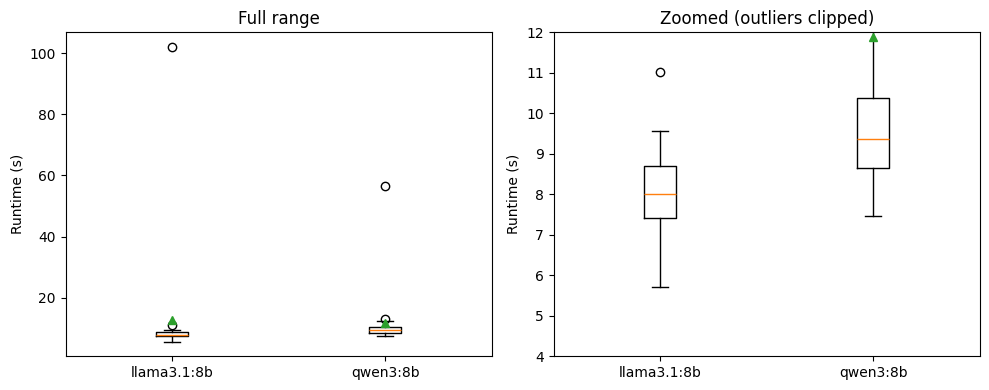

llama3.1:8b outliers:
   story_id  runtime_sec
0    US-001      101.956
19   US-020       11.015

qwen3:8b outliers:
  story_id  runtime_sec
0   US-001       56.468
2   US-003       13.219



In [18]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax in axes:
    ax.boxplot(
        [llama_meta_df["runtime_sec"], qwen_meta_df["runtime_sec"]],
        labels=["llama3.1:8b", "qwen3:8b"],
        showmeans=True,
    )
    ax.set_ylabel("Runtime (s)")

axes[0].set_title("Full range")
axes[1].set_ylim(4, 12)   # tighter zoom around the box/whisker range
axes[1].set_title("Zoomed (outliers clipped)")

plt.tight_layout()
plt.show()

# Report outliers separately
for name, df in [("llama3.1:8b", llama_meta_df), ("qwen3:8b", qwen_meta_df)]:
    q1, q3 = df["runtime_sec"].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = df[df["runtime_sec"] > q3 + 1.5 * iqr]
    if not outliers.empty:
        print(f"{name} outliers:\n{outliers[['story_id', 'runtime_sec']]}\n")

**Evaluation**


1. **Load Ground Truth and Predictions**: Load the ground truth and predictions from JSON files.
2. **Match Stories by Text**: Match stories from ground truth and predictions based on their text content.

In [19]:
def load_annotated_stories(path: Path) -> dict:
    print(path)
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def matching_stories_by_text(gt_stories: list[dict], pred_stories: list[dict]):
    remaining_pred_stories = list(pred_stories)
    matched_gt, match_pred = [], []

    for gt_story in gt_stories:
        gt_text = gt_story["Text"].strip()

        matched_index = next(
            (i for i,p in enumerate(remaining_pred_stories) if p["Text"] == gt_text), None
        )

        if matched_index is not None:
            matched_gt.append(gt_story)
            match_pred.append(remaining_pred_stories.pop(matched_index))

    extract_texts = {g["Text"].strip() for g in matched_gt}
    unmatched_gt = [g["Text"][:60] for g in gt_stories if g["Text"].strip() not in extract_texts]
    unmatched_pred = [p["Text"][:60] for p in remaining_pred_stories]

    return matched_gt, match_pred, unmatched_gt, unmatched_pred


In [20]:
gt_raw, pred_raw = None, None
try:
    gt_raw = load_annotated_stories(GT_PATH)
except FileNotFoundError:
    print(f"Ground truth file not found at {GT_PATH}. Please ensure the file exists.")

# try:
#     llama_pred_raw = load_annotated_stories(llama_PRED_PATH)
# except FileNotFoundError:
#     print(f"Predictions file not found at {llama_PRED_PATH}. Please ensure the file exists.")
# try:
#     qwen_pred_raw = load_annotated_stories(qwen_PRED_PATH)
# except FileNotFoundError:
#     print(f"Predictions file not found at {llama_PRED_PATH}. Please ensure the file exists.")


llama_gt, llama_pred, llama_unmatched_gt, llama_unmatched_pred = matching_stories_by_text(gt_raw, llama_results)
print(f"[llama] Aligned {len(llama_gt)} / {len(llama_pred)} stories.")
if llama_unmatched_gt:
    print(f"[llama] WARNING: Unmatched gold stories: {llama_unmatched_gt}")
if llama_unmatched_pred:
    print(f"[llama] WARNING: Unmatched prediction stories: {llama_unmatched_pred}")

qwen_gt, qwen_pred, qwen_unmatched_gt, qwen_unmatched_pred = matching_stories_by_text(gt_raw, qwen_results)
print(f"[qwen] Aligned {len(qwen_gt)} / {len(qwen_pred)} stories.")
if qwen_unmatched_gt:
    print(f"[qwen] WARNING: Unmatched gold stories: {qwen_unmatched_gt}")
if qwen_unmatched_pred:
    print(f"[qwen] WARNING: Unmatched prediction stories: {qwen_unmatched_pred}")

/content/BA_USDependency/eval_with_colab/annotation/baseline/20US_baseline.json
[llama] Aligned 20 / 20 stories.
[qwen] Aligned 20 / 20 stories.


### String-level matching rules

In [21]:
def normalize(text:str) -> str:
    return text.lower().strip()

#----------Extract---------------------#
def is_exact_match(phrase_a:str, phrase_b:str) -> bool:
    return normalize(phrase_a) == normalize(phrase_b)
#----------Included---------------------#
def is_included_match(phrase_a: str, phrase_b: str) -> bool:
    """True if the two phrases have the same word count and differ only by one pair of words where each is a substring of the other (e.g. a singular/plural pair), with every other word identical."""
    words_list_a = normalize(phrase_a).split()
    words_list_b = normalize(phrase_b).split()
    if len(words_list_a) != len(words_list_b):
        return False

    for word_x in words_list_a:
        for word_y in words_list_b:
            if word_x in word_y or word_y in word_x:
                rest_words_list_a = words_list_a.copy()
                rest_words_list_a.remove(word_x)

                rest_words_list_b = words_list_b.copy()
                rest_words_list_b.remove(word_y)
                if rest_words_list_a == rest_words_list_b:
                    return True
    return False

#------------------Relaxed-------------------#
def strip_qualifiers(text: str) -> str:
    """
    Drop function/qualifier words (POS-tagged via spaCy) and return what remains, e.g. "many datasets" -> "datasets".
    """
    doc = nlp(text)
    kept_words = []
    for token in doc:
        if token.pos_ not in QUALIFIER_POS_TAGS:
            kept_words.append(token.text)

    return " ".join(kept_words)


def is_relaxed_match(phrase_a: str, phrase_b: str) -> bool:
    if is_exact_match(phrase_a, phrase_b):
        return True
    return normalize(strip_qualifiers(phrase_a)) == normalize(strip_qualifiers(phrase_b))


### Pair-level rules

In [22]:
def compare_node_list(gt_items, pred_items, mode):
    gt_items = list(gt_items) # copy list
    true_positives = []
    remain_pred = []

    # Step 1 exact match
    for item in pred_items:
        match_index = None
        for i in range(len(gt_items)):
            if is_exact_match(item, gt_items[i]):
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            remain_pred.append(item)

    if mode == "strict":
        false_positives = remain_pred
        false_negatives = gt_items
        return true_positives, false_positives, false_negatives


    false_positives = []
    for predicted_item in remain_pred:
        match_index = None
        for i in range(len(gt_items)):
            if mode == "included":
                is_match = is_included_match(predicted_item, gt_items[i])
            else:  # relaxed
                is_match = is_relaxed_match(predicted_item, gt_items[i])
            if is_match:
                match_index = i
                break

        if match_index is not None:
            matched_item = gt_items.pop(match_index)
            true_positives.append(matched_item)
        else:
            false_positives.append(predicted_item)

    false_negatives = gt_items
    return true_positives, false_positives, false_negatives


In [23]:
def compare_edge_list(gt_edges, pred_edges, mode):
    gt_edges = [list(pair) for pair in gt_edges]  # copy
    true_positives = []
    leftover_predictions = []

    # step 1 exact match
    for predicted_pair in pred_edges:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            first_matches = is_exact_match(predicted_pair[0], gold_pair[0])
            second_matches = is_exact_match(predicted_pair[1], gold_pair[1])
            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            leftover_predictions.append(predicted_pair)

    if mode == "strict":
        false_positives = leftover_predictions
        false_negatives = gt_edges
        return true_positives, false_positives, false_negatives

    # Step 2 fall back
    false_positives = []
    for predicted_pair in leftover_predictions:
        match_index = None
        for i in range(len(gt_edges)):
            gold_pair = gt_edges[i]
            if mode == "included":
                first_matches = is_included_match(predicted_pair[0], gold_pair[0])
                second_matches = is_included_match(predicted_pair[1], gold_pair[1])
            else:  # relaxed
                first_matches = is_relaxed_match(predicted_pair[0], gold_pair[0])
                second_matches = is_relaxed_match(predicted_pair[1], gold_pair[1])

            if first_matches and second_matches:
                match_index = i
                break

        if match_index is not None:
            matched_pair = gt_edges.pop(match_index)
            true_positives.append(matched_pair)
        else:
            false_positives.append(predicted_pair)

    false_negatives = gt_edges
    return true_positives, false_positives, false_negatives


In [24]:
def precision_recall_f1(true_positive_count: int, false_positive_count: int, false_negative_count: int):
    precision = true_positive_count / (true_positive_count + false_positive_count) \
        if (true_positive_count + false_positive_count) else 0.0
    recall = true_positive_count / (true_positive_count + false_negative_count) \
        if (true_positive_count + false_negative_count) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return precision, recall, f1

In [25]:
SPAN_FIELD_NAMES = ["Persona", "GoalAction", "BenefitAction", "GoalEntity", "BenefitEntity", "benefit"]
PAIR_FIELD_NAMES = ["triggers", "targets", "contains"]

def getter_field_items(annotated_story, field_name):
    if field_name in ("GoalAction", "BenefitAction"):
        return annotated_story.get("Action", {}).get(field_name, [])
    elif field_name in ("GoalEntity", "BenefitEntity"):
        return annotated_story.get("Entity", {}).get(field_name, [])
    elif field_name in SPAN_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    elif field_name in PAIR_FIELD_NAMES:
        return annotated_story.get(field_name, [])
    else:
        raise ValueError(f"Unknown field name: {field_name}")


In [26]:
def evaluate_field(gt_stories, predicted_stories, field_name, field_type, mode):
    total_true_positives = 0
    total_false_positives = 0
    total_false_negatives = 0
    per_story_scores = []

    for i in range(len(gt_stories)):
        gt_story = gt_stories[i]
        predicted_story = predicted_stories[i]

        gt_items = getter_field_items(gt_story, field_name)
        predicted_items = getter_field_items(predicted_story, field_name)

        if field_type == "span":
            true_positives, false_positives, false_negatives = compare_node_list(gt_items, predicted_items, mode)
        else:  # "pair"
            true_positives, false_positives, false_negatives = compare_edge_list(gt_items, predicted_items, mode)

        total_true_positives += len(true_positives)
        total_false_positives += len(false_positives)
        total_false_negatives += len(false_negatives)

        story_precision, story_recall, story_f1 = precision_recall_f1(
            len(true_positives), len(false_positives), len(false_negatives)
        )
        per_story_scores.append({"precision": story_precision, "recall": story_recall, "f1": story_f1})

    precision, recall, f1 = precision_recall_f1(
        total_true_positives, total_false_positives, total_false_negatives
    )
    overall_result = {
        "tp": total_true_positives,
        "fp": total_false_positives,
        "fn": total_false_negatives,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }
    return overall_result, per_story_scores


In [27]:
def score_predictions(gt_stories, pred_stories):
    results = {}
    per_story = {}

    if pred_stories is None:
        return results, per_story

    for mode in MODES:
        results[mode] = {}
        per_story[mode] = {}

        for field_name in SPAN_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt_stories, pred_stories, field_name, "span", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

        for field_name in PAIR_FIELD_NAMES:
            overall_result, story_scores = evaluate_field(gt_stories, pred_stories, field_name, "pair", mode)
            results[mode][field_name] = overall_result
            per_story[mode][field_name] = story_scores

    return results, per_story

In [28]:
llama_results_scores, llama_per_story = score_predictions(llama_gt, llama_pred)
qwen_results_scores, qwen_per_story = score_predictions(qwen_gt, qwen_pred)

print("Done. Fields scored: " + str(SPAN_FIELD_NAMES + PAIR_FIELD_NAMES))

Done. Fields scored: ['Persona', 'GoalAction', 'BenefitAction', 'GoalEntity', 'BenefitEntity', 'benefit', 'triggers', 'targets', 'contains']


In [29]:
def build_summary(results_scores):
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    summary_rows = []
    for field_name in all_field_names:
        strict_f1 = results_scores["strict"][field_name]["f1"]
        inclusion_f1 = results_scores["included"][field_name]["f1"]
        relaxed_f1 = results_scores["relaxed"][field_name]["f1"]
        summary_rows.append({
            "field": field_name,
            "strict_f1": strict_f1,
            "included_f1": inclusion_f1,
            "relaxed_f1": relaxed_f1,
        })

    summary = pd.DataFrame(summary_rows)
    summary = summary.set_index("field")
    summary = summary.round(3)
    return summary

In [30]:
llama_summary = build_summary(llama_results_scores)
qwen_summary = build_summary(qwen_results_scores)

print("llama3.1:8b")
display(llama_summary)

print("qwen3:8b")
display(qwen_summary)

llama3.1:8b


,strict_f1,included_f1,relaxed_f1
field,,,
Persona,1.000,1.000,1.000
GoalAction,0.721,0.787,0.787
BenefitAction,0.634,0.634,0.732
GoalEntity,0.661,0.661,0.713
BenefitEntity,0.689,0.689,0.711
benefit,0.964,0.964,0.969
triggers,0.719,0.781,0.781
targets,0.317,0.317,0.403
contains,0.000,0.000,0.000


qwen3:8b


,strict_f1,included_f1,relaxed_f1
field,,,
Persona,1.000,1.000,1.000
GoalAction,0.873,0.873,0.873
BenefitAction,0.698,0.698,0.884
GoalEntity,0.748,0.748,0.748
BenefitEntity,0.731,0.731,0.774
benefit,0.993,0.993,0.993
triggers,0.857,0.857,0.857
targets,0.496,0.496,0.539
contains,0.050,0.050,0.050


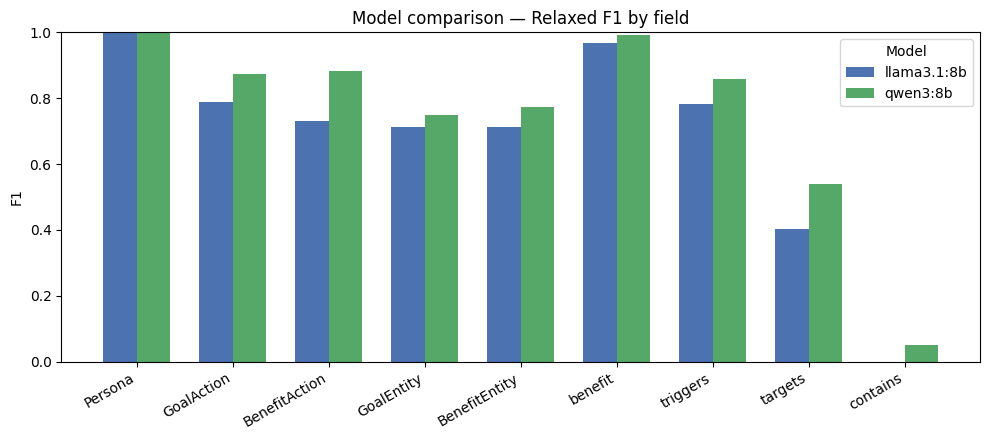

In [31]:
import numpy as np

def plot_model_comparison(llama_summary, qwen_summary, mode_column="relaxed_f1"):
    field_names = llama_summary.index.tolist()
    x_positions = np.arange(len(field_names))
    bar_width = 0.35

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x_positions - bar_width/2, llama_summary[mode_column], bar_width,
           label="llama3.1:8b", color="#4C72B0")
    ax.bar(x_positions + bar_width/2, qwen_summary[mode_column], bar_width,
           label="qwen3:8b", color="#55A868")

    ax.set_xticks(x_positions)
    ax.set_xticklabels(field_names, rotation=30, ha="right")
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1)
    ax.set_title(f"Model comparison — {mode_column.replace('_f1', '').capitalize()} F1 by field")
    ax.legend(title="Model")
    plt.tight_layout()
    plt.show()

plot_model_comparison(llama_summary, qwen_summary, mode_column="relaxed_f1")

In [38]:
def build_story_df(gt_stories, per_story_scores, run_results, run_meta):
    all_field_names = SPAN_FIELD_NAMES + PAIR_FIELD_NAMES

    # story_id -> runtime lookup, joined by Text (only stable shared key)
    runtime_by_text = {
        annotation["Text"].strip(): meta_row
        for annotation, meta_row in zip(run_results, run_meta["per_story"])
    }

    story_rows = []
    for story_index in range(len(gt_stories)):
        gt_story = gt_stories[story_index]

        field_f1_scores = []
        for field_name in all_field_names:
            story_score = per_story_scores["relaxed"][field_name][story_index]
            field_f1_scores.append(story_score["f1"])

        average_f1 = sum(field_f1_scores) / len(field_f1_scores)

        meta_row = runtime_by_text.get(gt_story["Text"].strip(), {})

        story_rows.append({
            "US_text": gt_story["Text"],
            "avg_f1_relaxed": average_f1,
            "runtime_sec": meta_row.get("runtime_sec"),
            "attempts": meta_row.get("attempts"),
        })

    story_df = pd.DataFrame(story_rows)
    story_df = story_df.sort_values("avg_f1_relaxed")
    story_df = story_df.reset_index(drop=True)
    return story_df


llama_story_df = build_story_df(llama_gt, llama_per_story, llama_results, llama_run_meta)
qwen_story_df = build_story_df(qwen_gt, qwen_per_story, qwen_results, qwen_run_meta)

In [44]:
print("llama3.1:8b — hardest stories (lowest F1):")
display(llama_story_df.sort_values("avg_f1_relaxed").head(5)[["US_text", "avg_f1_relaxed"]])

print("qwen3:8b — hardest stories (lowest F1):")
display(qwen_story_df.sort_values("avg_f1_relaxed").head(5)[["US_text", "avg_f1_relaxed"]])

llama3.1:8b — hardest stories (lowest F1):


,US_text,avg_f1_relaxed
0,"As a traveler, I want to import a location fro...",0.503202
1,"As a traveler, I want to select a destination,...",0.504890
2,"As a traveler, I want to attach private notes ...",0.587302
3,"As a traveler, I want to permanently delete a ...",0.591826
4,"As a traveler, I want to manually add a spot b...",0.600635


qwen3:8b — hardest stories (lowest F1):


,US_text,avg_f1_relaxed
0,"As a traveler, I want to drag and drop stops, ...",0.539197
1,"As a traveler, I want to remove a saved spot f...",0.562227
2,"As a new user, I want to sign up using my emai...",0.627022
3,"As a user, I want to walk through a short, gui...",0.657855
4,"As a traveler, I want to open the original Tik...",0.665748
